In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
columns = [
    'mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name'
]

df = pd.read_csv(
    './data/auto-mpg.data', 
    sep = r'\s+',
    names = columns,
    na_values = '?'
)

In [5]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [6]:
df.shape

(398, 9)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 34.4 KB


In [8]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


In [10]:
df.isna().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df[df['horsepower'].isna()]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
32,25.0,4,98.0,NaN,2046.0,19.0,71,1,ford pinto
126,21.0,6,200.0,NaN,2875.0,17.0,74,1,ford maverick
330,40.9,4,85.0,NaN,1835.0,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,NaN,2905.0,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,NaN,2320.0,15.8,81,2,renault 18i
374,23.0,4,151.0,NaN,3035.0,20.5,82,1,amc concord dl


In [13]:
df[df['horsepower'].isna()][
    ['car_name', 'cylinders', 'displacement', 'weight', 'mpg']
]

,car_name,cylinders,displacement,weight,mpg
32,ford pinto,4,98.0,2046.0,25.0
126,ford maverick,6,200.0,2875.0,21.0
330,renault lecar deluxe,4,85.0,1835.0,40.9
336,ford mustang cobra,4,140.0,2905.0,23.6
354,renault 18i,4,100.0,2320.0,34.5
374,amc concord dl,4,151.0,3035.0,23.0


In [18]:
#comparing for similar vehicles as those missing
df.loc[
    (df['cylinders'] == 4) & (df['displacement'].between(90, 120)),
    ['car_name', 'cylinders', 'displacement', 'horsepower']
]

,car_name,cylinders,displacement,horsepower
14,toyota corona mark ii,4,113.0,95.0
18,datsun pl510,4,97.0,88.0
19,volkswagen 1131 deluxe sedan,4,97.0,46.0
20,peugeot 504,4,110.0,87.0
21,audi 100 ls,4,107.0,90.0
...,...,...,...,...
384,honda civic (auto),4,91.0,67.0
385,datsun 310 gx,4,91.0,67.0
394,vw pickup,4,97.0,52.0
396,ford ranger,4,120.0,79.0


In [19]:
df.loc[df['horsepower'].isna(),
        ['car_name', 'cylinders', 'displacement', 'weight', 'mpg']]

,car_name,cylinders,displacement,weight,mpg
32,ford pinto,4,98.0,2046.0,25.0
126,ford maverick,6,200.0,2875.0,21.0
330,renault lecar deluxe,4,85.0,1835.0,40.9
336,ford mustang cobra,4,140.0,2905.0,23.6
354,renault 18i,4,100.0,2320.0,34.5
374,amc concord dl,4,151.0,3035.0,23.0


In [20]:
df.loc[
    df['horsepower'].isna(), ['car_name', 'cylinders', 'displacement', 'weight', 'model_year', 'origin']
]

,car_name,cylinders,displacement,weight,model_year,origin
32,ford pinto,4,98.0,2046.0,71,1
126,ford maverick,6,200.0,2875.0,74,1
330,renault lecar deluxe,4,85.0,1835.0,80,2
336,ford mustang cobra,4,140.0,2905.0,80,1
354,renault 18i,4,100.0,2320.0,81,2
374,amc concord dl,4,151.0,3035.0,82,1


In [22]:
df.loc[
    (df['cylinders'] == 4) &
    (df['model_year'].between(78, 82)) &
    (df['horsepower'].notna()), ['car_name', 'cylinders', 'displacement', 'weight', 'model_year', 'horsepower']
]

,car_name,cylinders,displacement,weight,model_year,horsepower
244,volkswagen rabbit custom diesel,4,90.0,1985.0,78,48.0
245,ford fiesta,4,98.0,1800.0,78,66.0
246,mazda glc deluxe,4,78.0,1985.0,78,52.0
247,datsun b210 gx,4,85.0,2070.0,78,70.0
248,honda civic cvcc,4,91.0,1800.0,78,60.0
...,...,...,...,...,...,...
393,ford mustang gl,4,140.0,2790.0,82,86.0
394,vw pickup,4,97.0,2130.0,82,52.0
395,dodge rampage,4,135.0,2295.0,82,84.0
396,ford ranger,4,120.0,2625.0,82,79.0


In [23]:
df.loc[
    (df['cylinders'] == 4) & 
    (df['model_year'].between(70, 72)) & 
    (df['horsepower'].notna()), ['car_name', 'displacement', 'weight', 'model_year', 'horsepower']
]

,car_name,displacement,weight,model_year,horsepower
14,toyota corona mark ii,113.0,2372.0,70,95.0
18,datsun pl510,97.0,2130.0,70,88.0
19,volkswagen 1131 deluxe sedan,97.0,1835.0,70,46.0
20,peugeot 504,110.0,2672.0,70,87.0
21,audi 100 ls,107.0,2430.0,70,90.0
22,saab 99e,104.0,2375.0,70,95.0
23,bmw 2002,121.0,2234.0,70,113.0
29,datsun pl510,97.0,2130.0,71,88.0
30,chevrolet vega 2300,140.0,2264.0,71,90.0
31,toyota corona,113.0,2228.0,71,95.0


In [24]:
pinto = df[
    (df['cylinders'] == 4) &
    (df['model_year'].between(70, 72)) &
    (df['displacement'].between(88, 108)) &
    (df['weight'].between(1900, 2300)) &
    (df['horsepower'].notna())
]

pinto[['car_name', 'displacement', 'weight', 'model_year', 'horsepower']]

,car_name,displacement,weight,model_year,horsepower
18,datsun pl510,97.0,2130.0,70,88.0
29,datsun pl510,97.0,2130.0,71,88.0
52,fiat 124b,88.0,2065.0,71,76.0
56,plymouth cricket,91.0,1955.0,71,70.0
58,dodge colt hardtop,97.5,2126.0,72,80.0
59,volkswagen type 3,97.0,2254.0,72,54.0
79,renault 12 (sw),96.0,2189.0,72,69.0
81,datsun 510 (sw),97.0,2288.0,72,92.0
83,dodge colt (sw),98.0,2164.0,72,80.0
84,toyota corolla 1600 (sw),97.0,2100.0,72,88.0


In [25]:
pinto['horsepower'].median()

np.float64(80.0)

In [26]:
len(pinto)

10

In [33]:
maverick = df[
    (df['cylinders'] == 6) &
    (df['displacement'].between(180, 220)) &
    (df['weight'].between(2600, 3200)) &
    (df['model_year'].between(72, 76)) &
    (df['horsepower'].notna())
]

maverick[['car_name', 'displacement', 'weight', 'model_year', 'horsepower']]

,car_name,displacement,weight,model_year,horsepower
101,plymouth duster,198.0,2904.0,73,95.0
125,plymouth duster,198.0,3102.0,74,95.0
193,ford maverick,200.0,3012.0,76,81.0


In [34]:
maverick['horsepower'].median()

np.float64(95.0)

since a similar make of the ford maverick exists (1976), the missing vsl will be imputed with this - 81 hp

In [35]:
df.loc[
    df['car_name'].str.contains('renault lecar', case = False, na = False), 
    ['car_name', 'cylinders', 'displacement', 'weight', 'model_year', 'horsepower']
]

,car_name,cylinders,displacement,weight,model_year,horsepower
330,renault lecar deluxe,4,85.0,1835.0,80,NaN


In [41]:
lecar = df[
    (df['cylinders'] == 4) &
    (df['displacement'].between(78, 89)) &
    (df['weight'].between(1750, 2050)) &
    (df['model_year'].between(78, 85)) &
    (df['origin'] == 2) &
    (df['horsepower'].notna())    
]

lecar[['car_name', 'cylinders', 'displacement', 'weight', 'model_year', 'horsepower']]

,car_name,cylinders,displacement,weight,model_year,horsepower
278,volkswagen scirocco,4,89.0,1990.0,78,71.0
293,vw rabbit custom,4,89.0,1925.0,79,71.0
332,vokswagen rabbit,4,89.0,1845.0,80,62.0


In [42]:
lecar['horsepower'].median()

np.float64(71.0)

In [43]:
df.loc[
    df['car_name'].str.contains('mustang', case = False, na = False), ['car_name', 'displacement', 'weight', 'model_year', 'horsepower']
]

,car_name,displacement,weight,model_year,horsepower
48,ford mustang,250.0,3139.0,71,88.0
166,ford mustang ii,302.0,3169.0,75,129.0
236,ford mustang ii 2+2,140.0,2755.0,77,89.0
336,ford mustang cobra,140.0,2905.0,80,NaN
393,ford mustang gl,140.0,2790.0,82,86.0


since mustang 

In [46]:
df.loc[df['car_name'] == 'ford mustang gl' ]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
393,27.0,4,140.0,86.0,2790.0,15.6,82,1,ford mustang gl


In [47]:
df.loc[
    df['car_name'].str.contains('Renault', na = False, case = False),
     ['car_name', 'displacement', 'weight', 'model_year', 'horsepower']
]

,car_name,displacement,weight,model_year,horsepower
79,renault 12 (sw),96.0,2189.0,72,69.0
186,renault 12tl,101.0,2202.0,76,83.0
218,renault 5 gtl,79.0,1825.0,77,58.0
330,renault lecar deluxe,85.0,1835.0,80,NaN
354,renault 18i,100.0,2320.0,81,NaN


the renault 12tl differs in displacement by 2 and weight differs by 118 and its by same manufacturer hence, its horsepower is adopted for the 18i ut first, verifying with other similar vehicles of same specs for any similarities

In [50]:
renault18i = df[
    (df['cylinders'] == 4) &
    (df['displacement'].between(90, 110)) &
    (df['weight'].between(2220, 2450)) &
    (df['horsepower'].notna()) &
    (df['model_year'].between(76,82)) &
    (df['origin'] == 2)
]

renault18i[['car_name', 'displacement', 'weight', 'model_year', 'horsepower']]

,car_name,displacement,weight,model_year,horsepower
326,vw dasher (diesel),90.0,2335.0,80,48.0


In [51]:
df.loc[
    df['car_name'].str.contains('concord', na = False, case = False),
    ['car_name', 'displacement', 'weight', 'model_year', 'horsepower']
]



,car_name,displacement,weight,model_year,horsepower
257,amc concord,232.0,3210.0,78,90.0
261,amc concord d/l,258.0,3410.0,78,120.0
283,amc concord dl 6,232.0,3265.0,79,90.0
315,amc concord,151.0,3003.0,80,90.0
374,amc concord dl,151.0,3035.0,82,NaN


In [54]:
imputed_hp = {
    'ford pinto': 80,
    'ford maverick': 81,
    'renault lecar deluxe': 71,
    'ford mustang cobra': 87.5,
    'renault 18i': 83,
    'amc concord dl':  90
}

In [53]:
df.loc[df['horsepower'].isna(), 'car_name'].tolist()

['ford pinto',
 'ford maverick',
 'renault lecar deluxe',
 'ford mustang cobra',
 'renault 18i',
 'amc concord dl']

In [55]:
df.isna().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

In [56]:
for car, hp in imputed_hp.items():
    df.loc[df['car_name'] == car, 'horsepower'] = hp

In [57]:
df.isna().sum()

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

## EDA



In [59]:
df['mpg'].describe()

count    398.000000
mean      23.514573
std        7.815984
min        9.000000
25%       17.500000
50%       23.000000
75%       29.000000
max       46.600000
Name: mpg, dtype: float64

In [60]:
df['mpg'].skew()

np.float64(0.45706634399491913)

<Axes: >

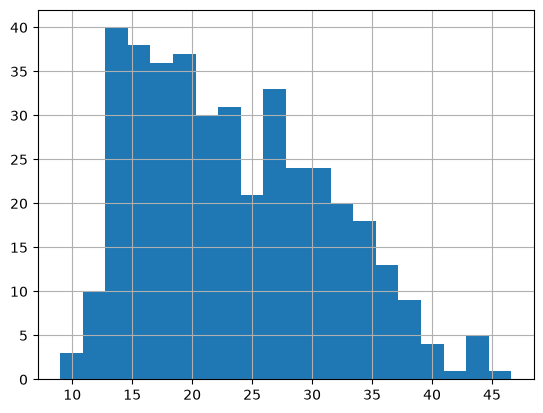

In [61]:
df['mpg'].hist(bins = 20)

In [62]:
df.corr(numeric_only=True)['mpg'].sort_values(ascending = False)

mpg             1.000000
model_year      0.579267
origin          0.563450
acceleration    0.420289
horsepower     -0.774756
cylinders      -0.775396
displacement   -0.804203
weight         -0.831741
Name: mpg, dtype: float64

above implies that newwer vehicles in the dataset tend to have better fuel efficiency, those from certain origins too the opposite holds for heavier vehicles, larger engine displacement, more cylinders and higher hp

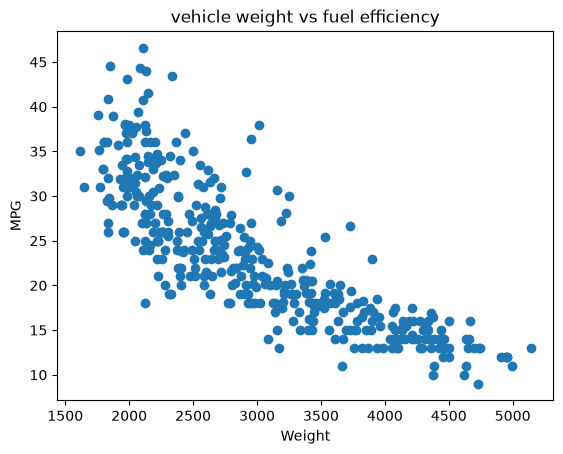

In [63]:
plt.scatter(df['weight'], df['mpg'])
plt.xlabel('Weight')
plt.ylabel('MPG')
plt.title('vehicle weight vs fuel efficiency')
plt.show();

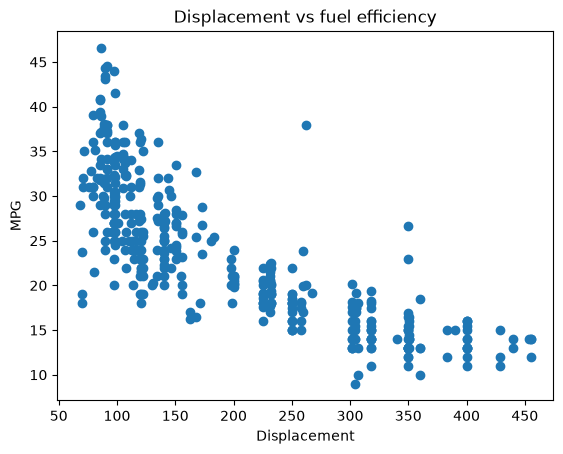

In [64]:
#dispplacement vs mpg
plt.scatter(df['displacement'], df['mpg'])
plt.xlabel('Displacement')
plt.ylabel('MPG')
plt.title('Displacement vs fuel efficiency')
plt.show();

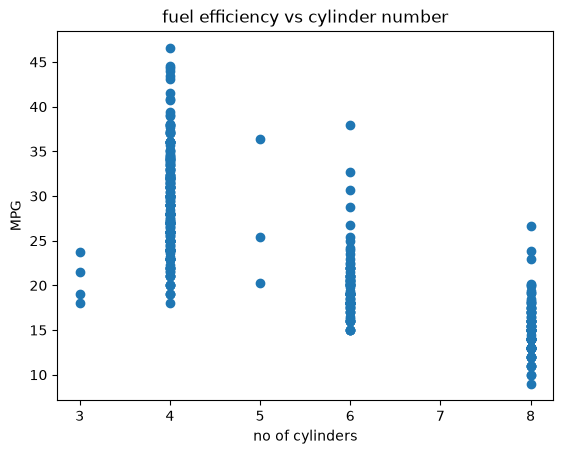

In [67]:
plt.scatter(df['cylinders'], df['mpg'])
plt.xlabel('no of cylinders')
plt.ylabel('MPG')
plt.title('fuel efficiency vs cylinder number')
plt.show();

## Modelling

In [68]:
x = df.drop(columns = ['mpg', 'car_name'])
y = df['mpg']

In [69]:
x.shape, y.shape

((398, 7), (398,))

In [70]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 10) 

In [71]:
x_train.shape, x_test.shape

((318, 7), (80, 7))

In [72]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy = 'mean')
baseline.fit(x_train, y_train)

ybase = baseline.predict(x_test)

In [73]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('R2 score: ', r2_score(y_test, ybase))
print('MAE: ', mean_absolute_error(y_test, ybase))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, ybase)))

R2 score:  -0.005558038461923154
MAE:  6.6451022012578616
RMSE:  7.841868417090053


In [75]:
from sklearn.linear_model import LinearRegression 
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

In [76]:
preprocessor = ColumnTransformer(
    transformers = [
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['cylinders', 'origin'])
    ],
    remainder = 'passthrough'
)

In [77]:
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

lr_pipeline.fit(x_train, y_train)
lrpred = lr_pipeline.predict(x_test)

In [78]:
print('R2: ', r2_score(y_test, lrpred))
print('MAE: ', mean_absolute_error(y_test, lrpred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, lrpred)))

R2:  0.8038327166496939
MAE:  2.712010332235464
RMSE:  3.4636122627650727


In [79]:
from sklearn.ensemble import RandomForestRegressor

In [80]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state = 10))
])

rf_pipeline.fit(x_train, y_train)
rfpred = rf_pipeline.predict(x_test)

In [81]:
print('RMSE: ', np.sqrt(mean_squared_error(y_test, rfpred)))
print('R2: ', r2_score(y_test, rfpred))
print('MAE: ', mean_absolute_error(y_test, rfpred))

RMSE:  2.851764081231125
R2:  0.8670172744209711
MAE:  2.118775000000001


In [82]:
#checking for overfitting
rf_pipeline.score(x_train, y_train)

0.9818110898598669

## Feature Importance


In [83]:
importance = pd.Series(
    rf_pipeline.named_steps['model'].feature_importances_,
    index = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()
).sort_values(ascending = False)

In [84]:
importance

remainder__displacement    0.363876
remainder__weight          0.239133
cat__cylinders_4           0.132840
remainder__model_year      0.117232
remainder__horsepower      0.113543
remainder__acceleration    0.024319
cat__origin_2              0.003371
cat__origin_3              0.002858
cat__origin_1              0.001234
cat__cylinders_6           0.000632
cat__cylinders_3           0.000504
cat__cylinders_5           0.000332
cat__cylinders_8           0.000125
dtype: float64

## Model Tuning

In [85]:
rf_tuned = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators = 100,
        max_depth = 10,
        min_samples_split = 10,
        min_samples_leaf = 5,
        random_state = 10
    ))
])

rf_tuned.fit(x_train, y_train)
tunedpred = rf_tuned.predict(x_test)

In [86]:
print('R2: ', r2_score(y_test, tunedpred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, tunedpred)))
print('MAE: ', mean_absolute_error(y_test, tunedpred))

R2:  0.8663133602474906
RMSE:  2.8593017058679435
MAE:  2.1231772112256286


In [87]:
#test for overfitting
rf_tuned.score(x_train, y_train)

0.9341754837543973

tuned model generalises better than the original model

In [89]:
# residuals of tuned model
residuals = y_test - tunedpred
residuals.describe()

count    80.000000
mean     -0.558901
std       2.821838
min      -7.946104
25%      -2.289785
50%      -0.396923
75%       0.771536
max       8.489385
Name: mpg, dtype: float64